# Finance task previews

Random samples for each finance task from the MTBench finance data.
Change `N` or `SEED` to see a different subset.

| Task | Data | Evaluation script |
|---|---|---|
| Time series forecasting | aligned pairs | `value_prediction.py --indicator time` |
| Trend prediction | aligned pairs | `trend_classification.py` |
| Technical indicators (MACD, Bollinger) | aligned pairs | `value_prediction.py --indicator macd/bb` |
| Correlation | `QAshort` / `QAlong` | `correlation_prediction.py` |
| Multiple-choice QA | `QAshort` / `QAlong` | `mcqa.py` |

In [1]:
import json
import random
import sys
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append("..")
from evaluation.finance.meta_prompt import (
    finance_correlation_metaprompt_generation,
    finance_mcqa_metaprompt_generation,
)

DATA = Path("../data/processed/finance")
N = 3
SEED = 0

# setting -> aligned-pairs folder and QA folder
ALIGNED = {
    "short (7 days in, 1 day out)": "aligned_in7days_out1days",
    "long (30 days in, 7 days out)": "aligned_in30days_out7days",
}
QA = {"short": "QAshort", "long": "QAlong"}


def load_aligned(folder):
    df = pd.read_parquet(DATA / folder / "data" / "train-00000-of-00001.parquet")
    for col in ["text", "trend", "technical", "alignment"]:
        df[col] = df[col].map(json.loads)
    return df


def sample_rows(df, n=N, seed=SEED):
    return df.loc[random.Random(seed).sample(list(df.index), n)]


def sample_files(folder, n=N, seed=SEED):
    files = sorted((DATA / folder).glob("*.json"))
    return random.Random(seed).sample(files, n)


def load(path):
    with open(path) as f:
        return json.load(f)


def short(text, n=400):
    text = " ".join(str(text).split())
    return text if len(text) <= n else text[:n] + " ..."


def when(ts):
    return datetime.fromtimestamp(ts).strftime("%Y-%m-%d %H:%M")


def plot_row(df, in_key, out_key, title_fn, in_label="input", out_label="output", n=N):
    fig, axes = plt.subplots(1, len(df), figsize=(5 * len(df), 3), squeeze=False)
    for ax, (idx, row) in zip(axes[0], df.iterrows()):
        x_in, x_out = in_key(row), out_key(row)
        ax.plot(range(len(x_in)), x_in, label=in_label)
        ax.plot(range(len(x_in), len(x_in) + len(x_out)), x_out, label=out_label)
        ax.set_title(title_fn(idx, row), fontsize=8)
        ax.legend(fontsize=7)
    plt.tight_layout()
    plt.show()


aligned = {setting: load_aligned(folder) for setting, folder in ALIGNED.items()}

## Aligned-pair tasks

Time series forecasting, trend prediction and technical indicators all read the same aligned files
(`input_window`, `output_window`, `text`, `trend`, `technical`), so one plot per sample is shown with each task's label.

### Time series forecasting

Time series forecasting | short (7 days in, 1 day out) | 750 samples


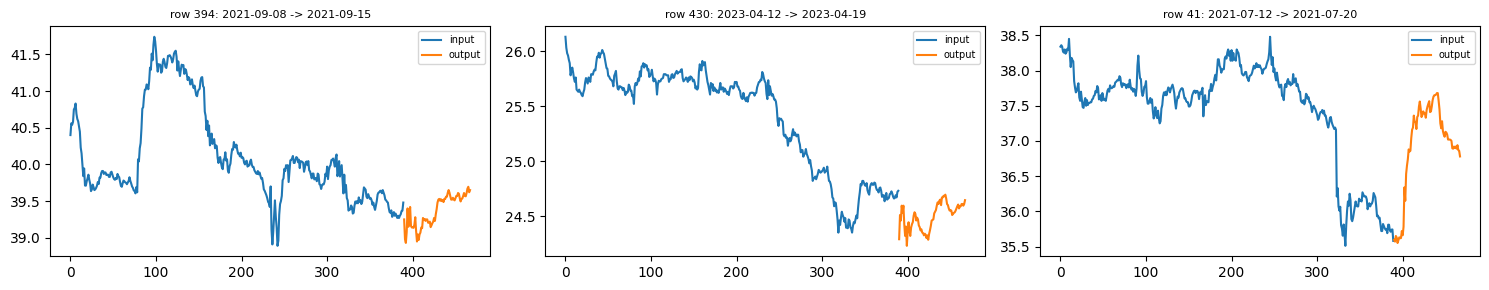

[row 394] predict 78 prices from 390 inputs
   news: Delta Air Lines (DAL) Dips More Than Broader Markets: What You Should Know By Zacks Equity Research Published on: 2021-09-14T21:50:18Z Delta Air Lines (DAL) closed the most recent trading day at $39.44, moving -1.84% from the previous trading session. Article Content: DAL Quick QuoteDAL Delta Air Lines (DAL Quick QuoteDAL - Free Report) closed the most recent trading day at $39.44, moving -1.84% f ...
[row 430] predict 78 prices from 390 inputs
   news: Marathon Oil (MRO) Stock Sinks As Market Gains: What You Should Know By Zacks Equity Research Published on: 2023-04-18T21:50:24Z In the latest trading session, Marathon Oil (MRO) closed at $24.74, marking a -0.24% move from the previous day. Article Content: MRO Quick QuoteMRO In the latest trading session, Marathon Oil (MRO Quick QuoteMRO - Free Report) closed at $24.74, marking a -0.24% move fro ...
[row 41] predict 78 prices from 390 inputs
   news: Cathay General (CATY) Earnings E

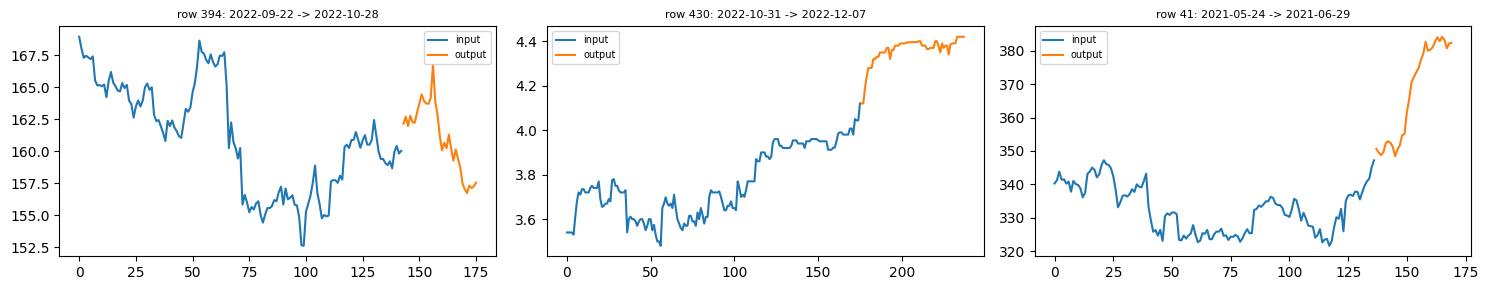

[row 394] predict 33 prices from 143 inputs
   news: Waste Management (WM) Gains But Lags Market: What You Should Know By Zacks Equity Research Published on: 2022-10-21T21:45:21Z Waste Management (WM) closed at $159.83 in the latest trading session, marking a +0.35% move from the prior day. Article Content: WM Quick QuoteWM Waste Management (WM Quick QuoteWM - Free Report) closed the most recent trading day at $159.83, moving +0.35% from the previou ...
[row 430] predict 62 prices from 176 inputs
   news: EDF annonce le succès de son émission obligataire hybride pour un montant nominal de 1 milliard d'euros et ainsi son intention d'exercer son option de remboursement des obligations hybrides USD en circulation By EDF Published on: 2022-11-30T17:36:00Z EDF annonce le succès de son émission obligataire hybride pour un montant nominal de 1 milliard d'euros et ainsi son intention d'exercer son option d ...
[row 41] predict 33 prices from 137 inputs
   news: Is Deckers (DECK) Stock a Solid 

In [2]:
for setting, df in aligned.items():
    print(f"{'=' * 100}\nTime series forecasting | {setting} | {len(df):,} samples")
    rows = sample_rows(df)
    plot_row(
        rows,
        lambda r: r["input_window"],
        lambda r: r["output_window"],
        lambda i, r: f"row {i}: {when(r['input_timestamps'][0])[:10]} -> {when(r['output_timestamps'][-1])[:10]}",
    )
    for idx, row in rows.iterrows():
        print(f"[row {idx}] predict {len(row['output_window'])} prices from {len(row['input_window'])} inputs")
        print("   news:", short(row["text"]["content"]))

### Trend prediction

Label is the 5-way bin of the output window's percentage change (`<-4%`, `-2% ~ -4%`, `-2% ~ +2%`, `+2% ~ +4%`, `>+4%`).

Trend prediction | short (7 days in, 1 day out)


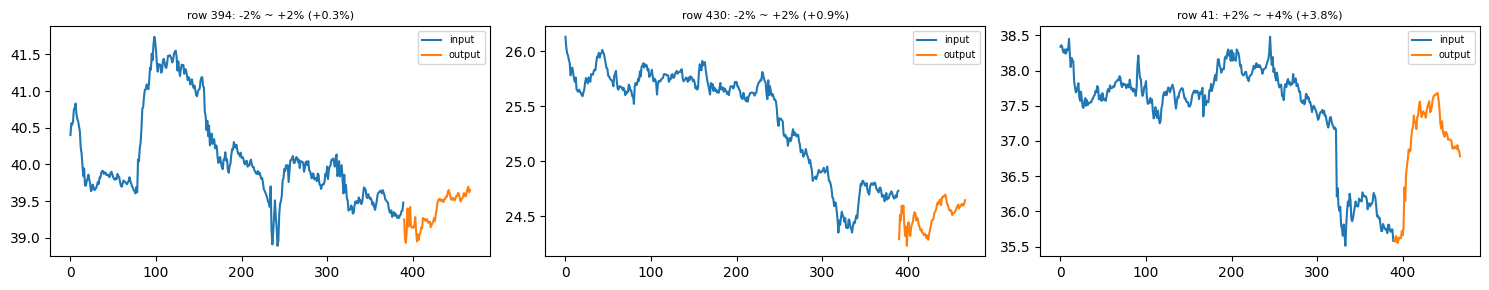

[row 394] output: -2% ~ +2% (+0.31%), input: -2% ~ +2%, alignment: consistent
   news: Delta Air Lines (DAL) Dips More Than Broader Markets: What You Should Know By Zacks Equity Research Published on: 2021-09-14T21:50:18Z Delta Air Lines (DAL) closed the most recent trading day at $39.44, moving -1.84% from the previous trading session. Article Content: DAL Quick QuoteDAL Delta Air Li ...
[row 430] output: -2% ~ +2% (+0.86%), input: -2% ~ -4%, alignment: consistent
   news: Marathon Oil (MRO) Stock Sinks As Market Gains: What You Should Know By Zacks Equity Research Published on: 2023-04-18T21:50:24Z In the latest trading session, Marathon Oil (MRO) closed at $24.74, marking a -0.24% move from the previous day. Article Content: MRO Quick QuoteMRO In the latest trading  ...
[row 41] output: +2% ~ +4% (+3.79%), input: -2% ~ -4%, alignment: consistent
   news: Cathay General (CATY) Earnings Expected to Grow: Should You Buy? By Zacks Equity Research Published on: 2021-07-19T19:00:56Z Catha

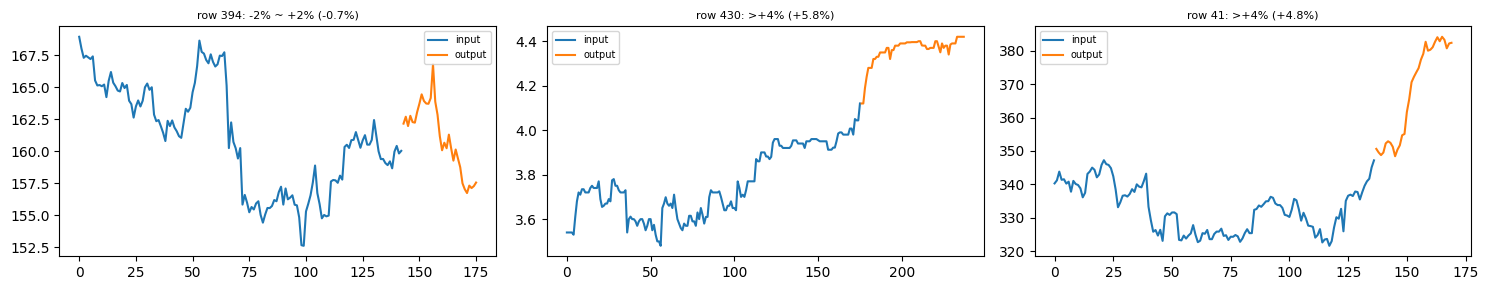

[row 394] output: -2% ~ +2% (-0.65%), input: <-4%, alignment: consistent
   news: Waste Management (WM) Gains But Lags Market: What You Should Know By Zacks Equity Research Published on: 2022-10-21T21:45:21Z Waste Management (WM) closed at $159.83 in the latest trading session, marking a +0.35% move from the prior day. Article Content: WM Quick QuoteWM Waste Management (WM Quick  ...
[row 430] output: >+4% (+5.81%), input: >+4%, alignment: consistent
   news: EDF annonce le succès de son émission obligataire hybride pour un montant nominal de 1 milliard d'euros et ainsi son intention d'exercer son option de remboursement des obligations hybrides USD en circulation By EDF Published on: 2022-11-30T17:36:00Z EDF annonce le succès de son émission obligataire ...
[row 41] output: >+4% (+4.83%), input: -2% ~ -4%, alignment: consistent
   news: Is Deckers (DECK) Stock a Solid Choice Right Now? By Zacks Equity Research Published on: 2021-06-23T12:41:00Z Deckers (DECK) has seen solid earnings e

In [3]:
for setting, df in aligned.items():
    print(f"{'=' * 100}\nTrend prediction | {setting}")
    rows = sample_rows(df)
    plot_row(
        rows,
        lambda r: r["input_window"],
        lambda r: r["output_window"],
        lambda i, r: f"row {i}: {r['trend']['output_bin_label']} ({r['trend']['output_percentage_change']:+.1f}%)",
    )
    for idx, row in rows.iterrows():
        t = row["trend"]
        print(
            f"[row {idx}] output: {t['output_bin_label']} ({t['output_percentage_change']:+.2f}%), "
            f"input: {t['input_bin_label']}, alignment: {row['alignment']}"
        )
        print("   news:", short(row["text"]["content"], 300))

### Technical indicators

MACD and the upper Bollinger band are predicted over the output window, from the input window's values.

Technical indicator: MACD | short (7 days in, 1 day out)


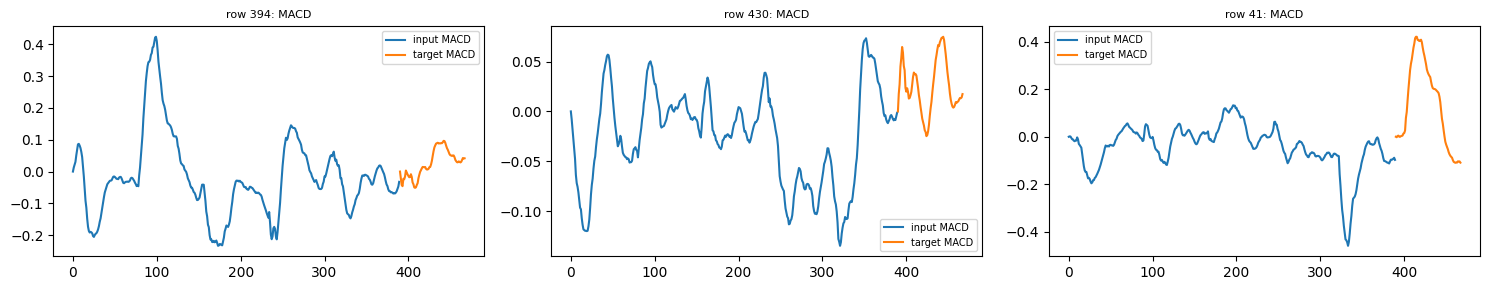

[row 394] 78 target values, first 0.000, last 0.042
[row 430] 78 target values, first 0.000, last 0.017
[row 41] 78 target values, first 0.000, last -0.109
Technical indicator: Upper Bollinger band | short (7 days in, 1 day out)


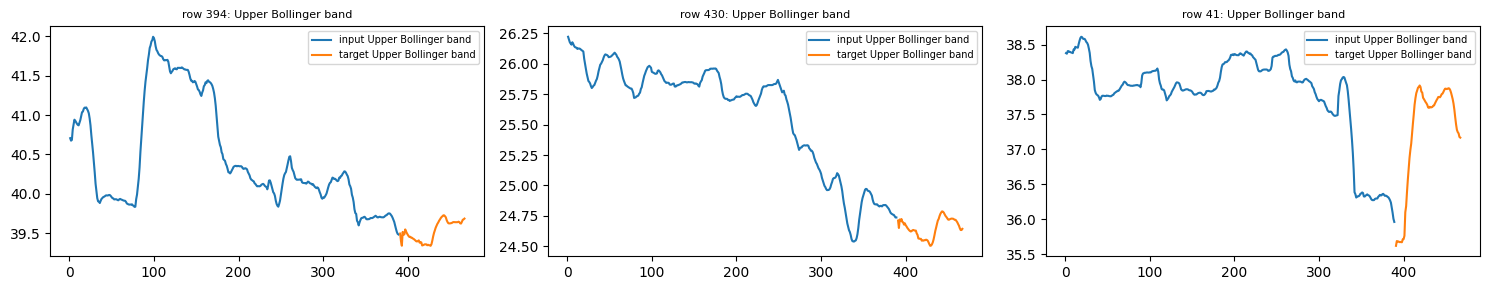

[row 394] 78 target values, first nan, last 39.687
[row 430] 78 target values, first nan, last 24.643
[row 41] 78 target values, first nan, last 37.168
Technical indicator: MACD | long (30 days in, 7 days out)


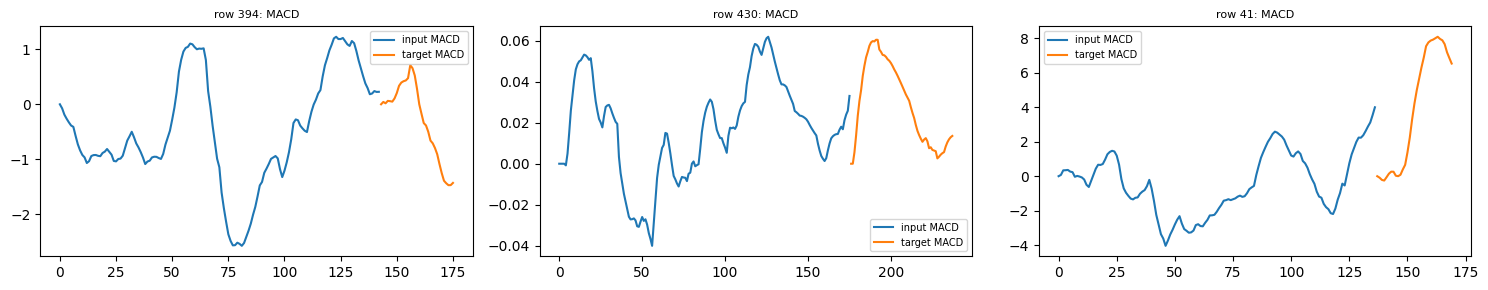

[row 394] 33 target values, first 0.000, last -1.429
[row 430] 62 target values, first 0.000, last 0.014
[row 41] 33 target values, first 0.000, last 6.523
Technical indicator: Upper Bollinger band | long (30 days in, 7 days out)


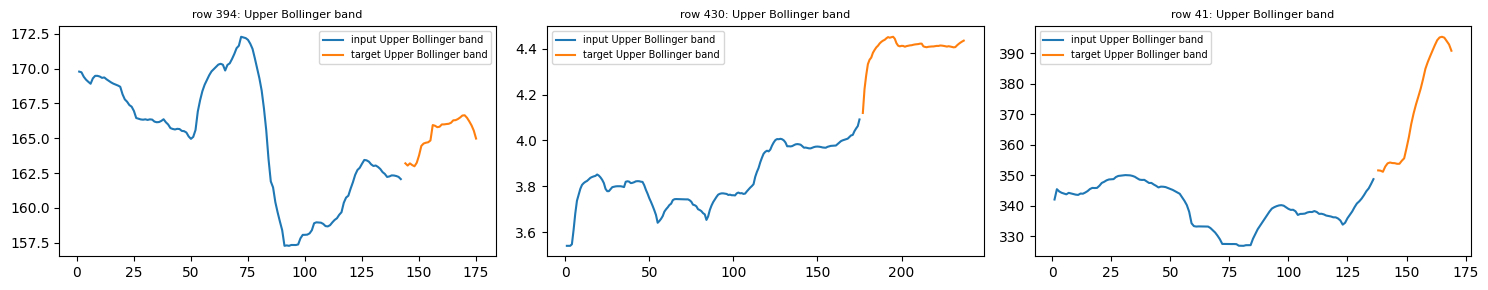

[row 394] 33 target values, first nan, last 164.973
[row 430] 62 target values, first nan, last 4.436
[row 41] 33 target values, first nan, last 390.870


In [4]:
for setting, df in aligned.items():
    for name, in_col, out_col in [("MACD", "in_macd", "out_macd"), ("Upper Bollinger band", "in_upper_bb", "out_upper_bb")]:
        print(f"{'=' * 100}\nTechnical indicator: {name} | {setting}")
        rows = sample_rows(df)
        plot_row(
            rows,
            lambda r: r["technical"][in_col],
            lambda r: r["technical"][out_col],
            lambda i, r: f"row {i}: {name}",
            in_label=f"input {name}",
            out_label=f"target {name}",
        )
        for idx, row in rows.iterrows():
            out = row["technical"][out_col]
            print(f"[row {idx}] {len(out)} target values, first {out[0]:.3f}, last {out[-1]:.3f}")

## Correlation

Predict how strongly the price movement correlates with the news sentiment (5 classes).

Correlation | short (QAshort)


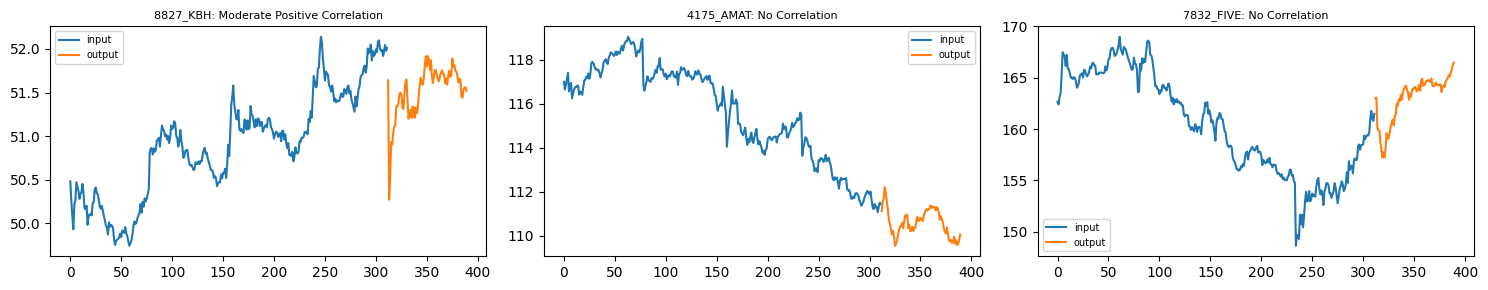

[8827_KBH.json] correlation: Moderate Positive Correlation (news published 2023-06-21T20:23:31Z)
   news: Title: KB Home Shares Climb On Q2 Earnings Beat, Strong Guidance Content: ["KB Home KBH shares are trading higher in Wednesday's after-hours session on the heels of the company's second-quarter report. Here's a rundown of the results and a look at what's driving the action.", 'What Happened: KB Home ...
[4175_AMAT.json] correlation: No Correlation (news published 2023-02-22T12:30:00Z)
   news: Title: Applied Materials to Participate at Morgan Stanley Technology, Media and Telecom Conference Content: ['\n\n\nFebruary 22, 2023 07:30 ET\n\n\r\n | Source:\r\n \nApplied Materials, Inc.\n\n\n\n\n\nApplied Materials, Inc.\n\r\n Santa Clara, California, UNITED STATES\r\n \n', '\r\n Santa Clara, C ...
[7832_FIVE.json] correlation: No Correlation (news published 2022-02-25T14:00:00Z)
   news: Title: Five Below, Inc. Announces Investor Day 2022 Including Fourth Quarter and Fiscal Year 2021 Re

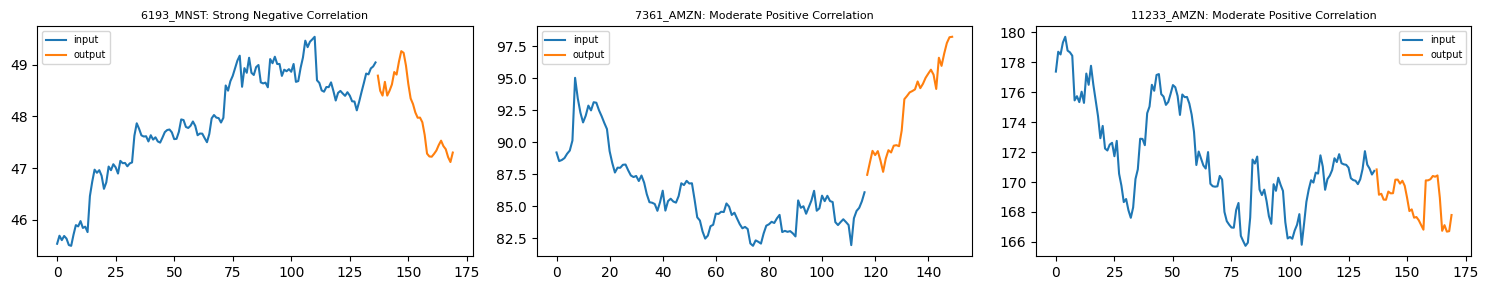

[6193_MNST.json] correlation: Strong Negative Correlation (news published 2021-04-29T21:06:37Z)
   news: Title: Monster Beverage (MNST) to Report Q1 Results: Wall Street Expects Earnings Growth Content: ['We use cookies to understand how you use our site and to improve your experience. This includes personalizing content and advertising. To learn more, click here. By continuing to use our site, you acc ...
[7361_AMZN.json] correlation: Moderate Positive Correlation (news published 2023-01-09T14:00:13Z)
   news: Title: Here is What to Know Beyond Why Amazon.com, Inc. (AMZN) is a Trending Stock Content: ['We use cookies to understand how you use our site and to improve your experience. This includes personalizing content and advertising. To learn more, click here. By continuing to use our site, you accept ou ...
[11233_AMZN.json] correlation: Moderate Positive Correlation (news published 2021-12-29T11:51:00Z)
   news: Title: Amazon Stock: Headed to $4,500? Content: ['Founded in 1993, The

In [5]:
for setting in QA:
    print(f"{'=' * 100}\nCorrelation | {setting} ({QA[setting]})")
    files = sample_files(QA[setting])
    fig, axes = plt.subplots(1, len(files), figsize=(5 * len(files), 3), squeeze=False)
    for ax, path in zip(axes[0], files):
        d = load(path)
        n_in = len(d["input_window"])
        ax.plot(range(n_in), d["input_window"], label="input")
        ax.plot(range(n_in, n_in + len(d["output_window"])), d["output_window"], label="output")
        ax.set_title(f"{path.stem}: {d['news_price_correlation']}", fontsize=8)
        ax.legend(fontsize=7)
    plt.tight_layout()
    plt.show()
    for path in files:
        d = load(path)
        print(f"[{path.name}] correlation: {d['news_price_correlation']} (news published {d['published_utc']})")
        print("   news:", short(d["text"], 300))

## Multiple-choice QA

In [6]:
for setting in QA:
    print(f"{'=' * 100}\nMCQA | {setting} ({QA[setting]})")
    for path in sample_files(QA[setting]):
        d = load(path)
        print(f"[{path.name}]")
        print("   news:", short(d["text"], 300))
        print("   question:", d["MCQA"]["question"].replace("\n", "\n             "))
        print("   answer:", d["MCQA"]["answer"])

MCQA | short (QAshort)
[8827_KBH.json]
   news: Title: KB Home Shares Climb On Q2 Earnings Beat, Strong Guidance Content: ["KB Home KBH shares are trading higher in Wednesday's after-hours session on the heels of the company's second-quarter report. Here's a rundown of the results and a look at what's driving the action.", 'What Happened: KB Home ...
   question: Which of the following statements about KBH's stock price and the given financial analysis is incorrect?
             A. Since KB Home's net order value decreased by 11% year-over-year, it is likely that the company will face bankruptcy within the next fiscal year.
             B. The announcement of KB Home's Q2 earnings beat likely contributed to an immediate uptick in its stock price, as evidenced by the after-hours increase to $52.59.
             C. The stock price movement from $50.48 to a peak of $52.59 suggests a positive market reaction and investor confidence following the strong earnings report and improved guidance

### Rendered prompts (series truncated)

One sample per setting showing the prompts `correlation_prediction.py` and `mcqa.py` build.

In [7]:
for setting in QA:
    path = sample_files(QA[setting], 1)[0]
    d = load(path)
    args = dict(
        setting=setting,
        sticker=path.name.split("_")[1].split(".")[0],
        time1=datetime.fromtimestamp(d["input_timestamps"][0]),
        time2=datetime.fromtimestamp(d["input_timestamps"][-1]),
        in_price=d["input_window"][:4] + ["..."],
        news=short(d["text"], 200),
        time_news=d["published_utc"],
    )
    print(f"--- correlation | {setting} ({path.name}) ---\n{finance_correlation_metaprompt_generation(**args)}\n")
    print(f"--- MCQA | {setting} ({path.name}) ---\n{finance_mcqa_metaprompt_generation(**args, question=d['MCQA']['question'])}\n")

--- correlation | short (8827_KBH.json) ---
You are an expert in finance and stock market analysis. Based on the given 7-day historical stock price time series and a financial analysis published at the last timestamp of the time series, your task is to predict the correlation between the stock's price fluctuations in the next 1 day and the analysis sentiment (positive correlation indicates that positive analysis leads to price increase and negative analysis leads to price decrease). Take into account external factors or market conditions that might affect stock price movement.

stock price of KBH between 2023-06-15 09:30:00 to 2023-06-21 15:55:00, time interval is 5 minutes:             [50.48, 50.26, 50.08, 49.93, '...']            News published at 2023-06-21T20:23:31Z:             Title: KB Home Shares Climb On Q2 Earnings Beat, Strong Guidance Content: ["KB Home KBH shares are trading higher in Wednesday's after-hours session on the heels of the company's second-quarter report ... 

## Dataset sizes

In [8]:
for setting, df in aligned.items():
    print(f"aligned pairs, {setting:32s} {len(df):>6,} samples")
for setting, folder in QA.items():
    print(f"QA {setting:8s} ({folder:8s}) {len(list((DATA / folder).glob('*.json'))):>6,} samples")

aligned pairs, short (7 days in, 1 day out)        750 samples
aligned pairs, long (30 days in, 7 days out)       525 samples
QA short    (QAshort )    491 samples
QA long     (QAlong  )    516 samples
